# F18 · Aligned FLIR v1 detectors: three backbones × two modalities, 2026-11-16

Comparison of the six full trainings of Roadmap **Phase 2b / F18**, launched on 2026-11-13 with

```bash
bash slurm/train_aligned.sh ctcomp3        # SLURM 5531172–5531177, git e66d526, 20 epochs each
```

Heads: `{dinopca, dino3072, mae} × {rgb, ir}` on aligned FLIR v1 (person + car, 2-way head), trained on aligned train
(3,707 frames) and selected on **aligned val** (413 frames, a contiguous id block carved from `align_train.txt`).

The three questions Table B asks (Roadmap F19):

1. **Paired H1**: does thermal beat RGB when frames *and* boxes are identical?
2. **PCA cost (R7)**: what does the fixed Cityscapes PCA (3072 → 1152) cost against a learned `Linear(3072 → 1152)`?
3. **DINOv2 vs MAE (R13)**: frozen DINOv2 + our stem vs MAE ViT-B fine-tuned end to end with stock ViTDet.

**Inputs, all read from `<repo>/outputs/`** (copied from the cluster's `$IRWM_OUTPUT_ROOT`; the notebook falls back to
`$IRWM_OUTPUT_ROOT` only if `outputs/` lacks the training runs):

| what | path under `outputs/` | used in |
|---|---|---|
| F18 training runs (offline W&B logs, `train_summary.json`) | `detection/2026-11-13/<time>/` | §1–§6, §8–§9 |
| F19 eval runs, test / val (`eval_aligned.json`; git `11ccb4d`, L4) | `detection/2026-11-16/17-54-19_slurm-553248{1,2}/` | §1 (export check), §7 |
| F19 saved detections (12 cells × 2 splits) | `detection/detections/<encoder_tag>/<head>/<modality>_<split>.json.gz` | §7 |
| F8 FLIR v2 runs, reference ratio only | `detection/2026-10-27/12-2{7-09,8-00}/val_metrics/` | §6 |

The GT boxes and the pixels (§6, §7) come from the local aligned dataset (`$IRWM_DATA_ROOT/aligned/align/`).

> **Scope: §1–§6 and §8–§9 are validation, not test.** Those numbers are on the 413-frame aligned **val** split, the
> split the checkpoint was *selected* on (so best-epoch values are slightly optimistic). The F19 evaluation on the
> held-out aligned test set (`align_validation`, 1,013 frames, 2×2 incl. cross-modal) has been run (2026-11-16);
> §7 uses its detections on both splits. No bootstrap CIs (F6 is not built), so differences of ≈ 0.01 AP should
> be read as ties.

In [1]:
import hashlib
import json
import struct
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from wandb.proto import wandb_internal_pb2 as pb

from irwm.utils.paths import load_env, output_root, repo_root

load_env()  # IRWM_DATA_ROOT for the GT and pixels (§6, §7)

# Everything comes from <repo>/outputs (cluster outputs copied back); $IRWM_OUTPUT_ROOT only if the runs are not there.
OUT = repo_root() / "outputs"
if not (OUT / "detection/2026-11-13").is_dir():
    OUT = output_root()
DAY = OUT / "detection/2026-11-13"
BACKBONES = ["dinopca", "dino3072", "mae"]
MODS = ["rgb", "ir"]
HEADS = [f"aligned_{b}_{m}" for b in BACKBONES for m in MODS]
JOBS = {  # SLURM job of each full run (slurm/train_aligned.sh ctcomp3, git e66d526)
    "aligned_dinopca_rgb": 5531172, "aligned_dinopca_ir": 5531173,
    "aligned_dino3072_rgb": 5531174, "aligned_dino3072_ir": 5531175,
    "aligned_mae_rgb": 5531176, "aligned_mae_ir": 5531177,
}
EPOCHS, LR_DROP_EPOCH = 20, 14  # F18 schedule: lr 1e-4 for epochs 0-13, x0.1 for 14-19


def read_json(path):
    return json.loads(Path(path).read_text())


def find_f19_run(split):
    """The latest F19 run (eval_aligned.json, mode=run) on `split` under OUT/detection/<date>/<time>/."""
    runs = [(r["created_at"], p, r) for p in sorted((OUT / "detection").glob("*/*/eval_aligned.json"))
            for r in [read_json(p)] if r.get("mode") == "run" and r.get("split") == split
            and r.get("dataset") == "aligned_v1"]
    assert runs, f"no F19 eval_aligned.json for split={split} under {OUT / 'detection'}"
    _, path, run = max(runs, key=lambda t: t[0])
    assert sorted(run["heads"]) == sorted(HEADS), (path, sorted(run["heads"]))
    return path, run


F19 = {s: find_f19_run(s) for s in ("val", "test")}  # split -> (eval_aligned.json path, its content)


def wandb_history(path):
    """History rows of an offline `.wandb` log (LevelDB-style log of `wandb.proto.Record`s).

    Same reader as detector_training_results.ipynb: 7-byte header, 32 KiB blocks, chunks with a
    7-byte crc/length/type header (1 = full record, 2/3/4 = first/middle/last fragment).
    """
    data = Path(path).read_bytes()
    assert data[:4] == b":W&B", path
    rows, pos, buf = [], 7, b""
    while pos + 7 <= len(data):
        left = 32768 - pos % 32768
        if left < 7:
            pos += left
            continue
        _, n, kind = struct.unpack("<IHB", data[pos:pos + 7])
        pos += 7
        if kind == 0:
            pos += left - 7
            continue
        buf += data[pos:pos + n]
        pos += n
        if kind not in (1, 4):
            continue
        rec = pb.Record()
        rec.ParseFromString(buf)
        buf = b""
        if rec.HasField("history"):
            rows.append({i.key or "/".join(i.nested_key): json.loads(i.value_json) for i in rec.history.item})
    return rows


# Find each head's W&B run by the `aligned=<head>` override in its own wandb-metadata.json, NOT by run dir:
# the two dinopca jobs started in the same second and shared the run dir 17-43-00 (§1).
WB = {}
for meta_path in sorted(DAY.glob("*/wandb/run-*/files/wandb-metadata.json")):
    meta = read_json(meta_path)
    (head,) = [a.split("=", 1)[1] for a in meta["args"] if a.startswith("aligned=")]
    if head not in JOBS or "smoke.enabled=true" in meta["args"]:
        continue
    run = meta_path.parents[1]
    assert head not in WB, f"two W&B runs for {head}"
    WB[head] = {"run_dir": run.parents[1], "id": run.name.split("-")[-1], "meta": meta,
                "hist": wandb_history(next(run.glob("run-*.wandb")))}
assert sorted(WB) == sorted(HEADS), sorted(WB)

# train_summary.json is trusted only when its own `name` is that head (the shared dir keeps the last writer's).
SUMMARY = {}
for h in HEADS:
    p = WB[h]["run_dir"] / "train_summary.json"
    s = read_json(p) if p.exists() else None
    SUMMARY[h] = s if s and s["name"] == h else None


def series(h, key, x="trainer/global_step"):
    rows = [r for r in WB[h]["hist"] if key in r]
    return np.array([r[x] for r in rows], float), np.array([r[key] for r in rows], float)


def per_epoch(h, key):
    ep, y = series(h, key, x="epoch")
    assert np.array_equal(ep, np.arange(EPOCHS)), f"{h}: {key} not logged once per epoch"
    return y


VAL_KEYS = ["AP", "AP50", "AP75", "APs", "APm", "APl", "AP_person", "AP50_person", "AP_car", "AP50_car"]
VAL = {h: {k: per_epoch(h, f"val/{k}") for k in VAL_KEYS} for h in HEADS}
BEST = {h: int(np.argmax(VAL[h]["AP"])) for h in HEADS}  # ModelCheckpoint(monitor="val/AP", mode="max")

# Where a valid summary exists, W&B must reproduce it exactly (same numbers, same best epoch).
for h, s in SUMMARY.items():
    if s is None:
        continue
    assert s["best_epoch"] == BEST[h], h
    for e, v in enumerate(s["validations"]):
        assert all(np.isclose(v["metrics"][k], VAL[h][k][e]) for k in VAL_KEYS), (h, e)

print(f"output root: {OUT}")
for h in HEADS:
    print(f"{h:22s} job {JOBS[h]}  dir {WB[h]['run_dir'].name}  W&B {WB[h]['id']}  "
          f"{len(WB[h]['hist'])} rows  summary: {'ok' if SUMMARY[h] else 'MISSING (overwritten)'}")
for s, (p, r) in F19.items():
    d = r["device"]
    print(f"F19 {s:4s}: {p.relative_to(OUT)}  git {r['git']['commit'][:7]}{' dirty' if r['git']['dirty'] else ''}, "
          f"{d['name']} on {d['slurm_node']}, {r['n_images']['rgb']} frames")

output root: /home/leonardo.ulloa/projects/ir-world-model/outputs
aligned_dinopca_rgb    job 5531172  dir 17-43-00  W&B 7y04wjbd  134 rows  summary: ok
aligned_dinopca_ir     job 5531173  dir 17-43-00  W&B 4axkuf1b  134 rows  summary: MISSING (overwritten)
aligned_dino3072_rgb   job 5531174  dir 17-43-03  W&B ajq1dvpf  134 rows  summary: ok
aligned_dino3072_ir    job 5531175  dir 17-43-10  W&B oc4lodu7  134 rows  summary: ok
aligned_mae_rgb        job 5531176  dir 18-28-58  W&B z03gpl54  134 rows  summary: ok
aligned_mae_ir         job 5531177  dir 18-28-59  W&B 2oyclyf5  134 rows  summary: ok
F19 val : detection/2026-11-16/17-54-19_slurm-5532482/eval_aligned.json  git 11ccb4d, NVIDIA L4 on hpc-gpu6, 413 frames
F19 test: detection/2026-11-16/17-54-19_slurm-5532481/eval_aligned.json  git 11ccb4d, NVIDIA L4 on hpc-gpu6, 1013 frames


**Run-dir collision.** `aligned_dinopca_rgb` and `aligned_dinopca_ir` started in the same second and Hydra gave both
the run dir `2026-11-13/17-43-00` (the `_${run_name}` suffix that fixes this landed in `548c50b`, after `e66d526`).
In that dir, `train_summary.json`, `.hydra/` and `val_metrics/epoch_*.json` hold whichever job wrote last
(dinopca_rgb), so **none of them can be trusted for dinopca_ir**. Both W&B runs kept their own folder
(`7y04wjbd` = RGB, `4axkuf1b` = IR), so this notebook reads every metric from the per-run offline `.wandb` logs and
identifies each run by its own `aligned=` override. Wherever an intact `train_summary.json` exists, the cell above
asserts that W&B reproduces it exactly (all 20 validations and the best epoch), which holds for the five other heads.
The frozen exports and checkpoints went to per-job paths and are not affected.

In [2]:
# Style as in detector_training_results.ipynb: modality is the only colour (RGB blue, thermal orange);
# backbones are small multiples / line styles, never extra hues.
MOD_COLOR = {"rgb": "#2a78d6", "ir": "#eb6834"}
MOD_LABEL = {"rgb": "RGB", "ir": "Thermal"}
BB_LABEL = {"dinopca": "DINOv2 + PCA", "dino3072": "DINOv2 3072 → Linear", "mae": "MAE ViT-B (fine-tuned)"}
BB_LS = {"dinopca": "-", "dino3072": "--", "mae": ":"}
INK, MUTED, GRID, REF = "#0b0b0b", "#52514e", "#e6e5e0", "#a8a7a2"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def bb(h):
    return h.split("_")[1]


def mod(h):
    return h.split("_")[2]


def table(header, rows):
    fmt = lambda v: f"{v:.3f}" if isinstance(v, (float, np.floating)) else ("–" if v is None else str(v))
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(fmt(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))


def mark_lr_drop(ax):
    ax.axvline(LR_DROP_EPOCH - 0.5, color=REF, lw=1, ls="--", zorder=0)
    ax.text(LR_DROP_EPOCH - 0.3, 1, "lr ×0.1", transform=ax.get_xaxis_transform(), ha="left", va="top",
            fontsize=7.5, color=MUTED)

## 1. Runs and provenance

GPU and host from each run's W&B metadata; GPU-hours and step time logged by `DetectorModule`; peak memory from
`train_summary.json` (lost for dinopca_ir, *commit taken from the shared submission).

In [3]:
rows = []
for h in HEADS:
    m, s = WB[h]["meta"], SUMMARY[h]
    step_ms = np.median(per_epoch(h, "perf/step_ms"))
    gpu_h = series(h, "perf/gpu_hours")[1][-1]
    rows.append([h, JOBS[h], m["host"], m["gpu"].replace("NVIDIA ", "").replace("Tesla ", ""), f"`{WB[h]['id']}`",
                 f"`{s['git']['commit'][:7]}`" if s else "`e66d526`*",
                 f"{int(series(h, 'data/n_train_frames')[1][0]):,}", f"{int(series(h, 'data/n_val_frames')[1][0])}",
                 f"{step_ms:.0f}", f"{gpu_h:.2f}", f"{s['peak_mem_gib']:.1f}" if s else None,
                 int(series(h, "train/nonfinite_steps")[1].max())])
table(["head", "job", "host", "GPU", "W&B", "commit", "train frames", "val frames", "median step ms",
       "GPU-h (fit)", "peak GiB", "non-finite steps"], rows)

# The frozen exports F19 evaluated (their meta.json, copied into eval_aligned.json) against the W&B logs:
# the exported checkpoint must be the best epoch, and its recorded val metrics should be that epoch's.
EXPORT = F19["test"][1]["heads"]
assert all(EXPORT[h] == F19["val"][1]["heads"][h] for h in HEADS)  # both F19 runs used the same exports
rows, BAD_META = [], []
for h in HEADS:
    e = EXPORT[h]
    vm = e["val_metrics"]["metrics"]
    ok = all(np.isclose(vm[k], VAL[h][k][BEST[h]]) for k in VAL_KEYS)
    if not ok:
        BAD_META.append(h)
    assert e["epoch"] == BEST[h] and f"slurm-{JOBS[h]}/" in e["source_ckpt"], (h, e["epoch"], e["source_ckpt"])
    rows.append([h, f"`{e['source_ckpt']}`", e["epoch"], BEST[h], vm["AP"], VAL[h]["AP"][BEST[h]],
                 "ok" if ok else "**MISMATCH**"])
display(Markdown("**Frozen exports used by F19 vs the W&B logs**"))
table(["head", "exported checkpoint", "export epoch", "W&B best epoch", "meta.json val AP", "W&B val AP @best",
       "meta metrics = W&B"], rows)

| head | job | host | GPU | W&B | commit | train frames | val frames | median step ms | GPU-h (fit) | peak GiB | non-finite steps |
|---|---|---|---|---|---|---|---|---|---|---|---|
| aligned_dinopca_rgb | 5531172 | hpc-gpu1 | V100S-PCIE-32GB | `7y04wjbd` | `e66d526` | 3,707 | 413 | 765 | 1.08 | 18.2 | 0 |
| aligned_dinopca_ir | 5531173 | hpc-gpu1 | V100S-PCIE-32GB | `4axkuf1b` | `e66d526`* | 3,707 | 413 | 762 | 1.07 | – | 0 |
| aligned_dino3072_rgb | 5531174 | hpc-gpu3 | A100-PCIE-40GB | `ajq1dvpf` | `e66d526` | 3,707 | 413 | 524 | 0.74 | 18.8 | 0 |
| aligned_dino3072_ir | 5531175 | hpc-gpu3 | A100-PCIE-40GB | `oc4lodu7` | `e66d526` | 3,707 | 413 | 527 | 0.74 | 18.7 | 0 |
| aligned_mae_rgb | 5531176 | hpc-gpu3 | A100-PCIE-40GB | `z03gpl54` | `e66d526` | 3,707 | 413 | 880 | 1.24 | 19.8 | 0 |
| aligned_mae_ir | 5531177 | hpc-gpu3 | A100-PCIE-40GB | `2oyclyf5` | `e66d526` | 3,707 | 413 | 876 | 1.23 | 19.8 | 0 |

**Frozen exports used by F19 vs the W&B logs**

| head | exported checkpoint | export epoch | W&B best epoch | meta.json val AP | W&B val AP @best | meta metrics = W&B |
|---|---|---|---|---|---|---|
| aligned_dinopca_rgb | `detection/slurm-5531172/best-e016.ckpt` | 16 | 16 | 0.174 | 0.174 | ok |
| aligned_dinopca_ir | `detection/slurm-5531173/best-e016.ckpt` | 16 | 16 | 0.174 | 0.412 | **MISMATCH** |
| aligned_dino3072_rgb | `detection/slurm-5531174/best-e018.ckpt` | 18 | 18 | 0.173 | 0.173 | ok |
| aligned_dino3072_ir | `detection/slurm-5531175/best-e018.ckpt` | 18 | 18 | 0.420 | 0.420 | ok |
| aligned_mae_rgb | `detection/slurm-5531176/best-e014.ckpt` | 14 | 14 | 0.157 | 0.157 | ok |
| aligned_mae_ir | `detection/slurm-5531177/best-e018.ckpt` | 18 | 18 | 0.417 | 0.417 | ok |

- All six jobs finished their 20 epochs with no requeue and **zero non-finite steps**, and all exported a frozen head.
- **The GPUs differ**: both dinopca heads landed on a V100S, the four others on an A100-40GB, so step times
  are comparable only within the same GPU (§9). None ran on an L4, so the time limits (sized for L4) had ample margin.
- Same data for all: 3,707 train frames (3 frames with no person/car box dropped), 413 val frames.
- **Frozen exports (second table).** Every head F19 evaluated is its own job's best-epoch checkpoint
  (`slurm-<job>/best-e<epoch>.ckpt`, epoch = W&B best). One defect: **`aligned_dinopca_ir`'s `meta.json` records the
  RGB head's val metrics** (AP 0.174 instead of 0.412), because the export read them from the shared run dir 17-43-00.
  Only the metadata is wrong. The weights are the thermal head's: F19's val re-score of that export gives in-domain
  AP50 0.798 against 0.797 in its W&B log (§7). Do not quote val metrics from that `meta.json`.

## 2. Validation curves

COCO AP (person + car, IoU 0.5:0.95) on aligned val after every epoch. ★ = best `val/AP`, i.e. the exported checkpoint.
The dashed line is the lr drop (×0.1 from epoch 14).

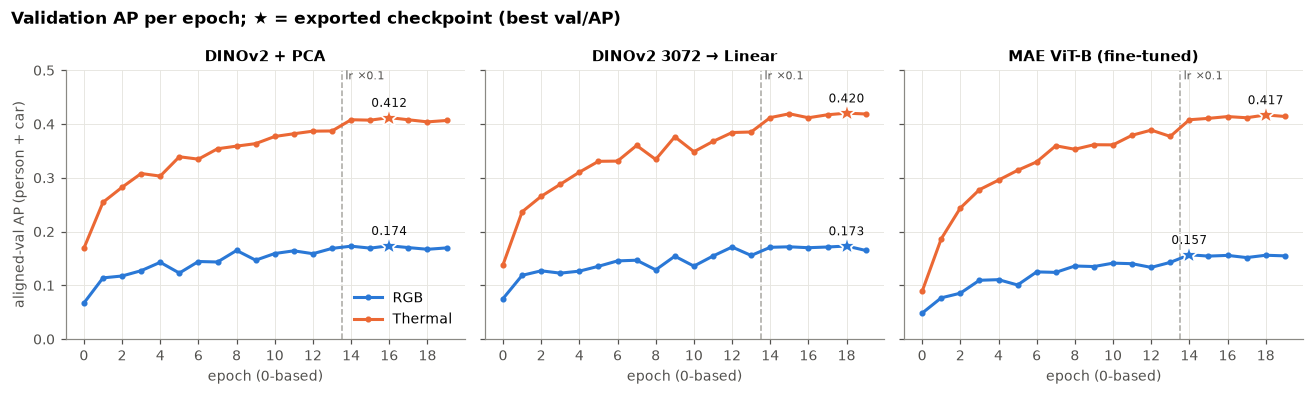

In [4]:
x = np.arange(EPOCHS)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, b in zip(axes, BACKBONES):
    for m in MODS:
        h = f"aligned_{b}_{m}"
        ax.plot(x, VAL[h]["AP"], color=MOD_COLOR[m], lw=2, marker="o", ms=3, label=MOD_LABEL[m])
        e = BEST[h]
        ax.plot(e, VAL[h]["AP"][e], marker="*", ms=13, color=MOD_COLOR[m], mec="white", mew=1.2, zorder=5)
        ax.annotate(f"{VAL[h]['AP'][e]:.3f}", (e, VAL[h]["AP"][e]), xytext=(0, 7), textcoords="offset points",
                    ha="center", fontsize=8, color=INK)
    mark_lr_drop(ax)
    ax.set_title(BB_LABEL[b])
    ax.set_xlabel("epoch (0-based)")
    ax.set_xticks(range(0, EPOCHS, 2))
axes[0].set_ylabel("aligned-val AP (person + car)")
axes[0].set_ylim(0, 0.5)
axes[0].legend(loc="lower right")
fig.suptitle("Validation AP per epoch; ★ = exported checkpoint (best val/AP)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

- **The modality gap dwarfs every backbone difference.** Every thermal head ends at 0.41–0.42 AP, every RGB head at
  0.16–0.17. The gap is there from epoch 0 and widens through training.
- **The lr drop helps every head** (+0.005 to +0.035 AP between epoch 13 and the best epoch), most for thermal:
  dino3072_ir 0.385 → 0.420, mae_ir 0.377 → 0.417.
- **No overfitting within 20 epochs**: the last-5-epoch AP varies by ≤ 0.003 (std) and epoch 19 is within 0.008
  of the best for every head. Unlike F8's RGB head, nothing peaks and decays, and the thermal curves are still
  almost flat-rising, so a longer low-lr phase might add a little for thermal.
- Best epochs: dinopca 16 / 16, dino3072 18 / 18, MAE 14 (RGB) / 18 (thermal).

## 3. Best-checkpoint table (aligned val)

The val metrics of the exported checkpoint of each head. APs/m/l use areas normalised to 640×512.

In [5]:
COLS = ["AP", "AP50", "AP75", "AP_person", "AP50_person", "AP_car", "AP50_car", "APs", "APm", "APl"]
B = {h: {k: VAL[h][k][BEST[h]] for k in VAL_KEYS} for h in HEADS}
table(["backbone", "modality", "best epoch"] + COLS,
      [[BB_LABEL[bb(h)], MOD_LABEL[mod(h)], BEST[h]] + [B[h][k] for k in COLS] for h in HEADS])

| backbone | modality | best epoch | AP | AP50 | AP75 | AP_person | AP50_person | AP_car | AP50_car | APs | APm | APl |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| DINOv2 + PCA | RGB | 16 | 0.174 | 0.485 | 0.085 | 0.107 | 0.353 | 0.241 | 0.618 | 0.088 | 0.301 | 0.400 |
| DINOv2 + PCA | Thermal | 16 | 0.412 | 0.797 | 0.363 | 0.365 | 0.767 | 0.459 | 0.828 | 0.289 | 0.589 | 0.716 |
| DINOv2 3072 → Linear | RGB | 18 | 0.173 | 0.485 | 0.087 | 0.096 | 0.348 | 0.250 | 0.622 | 0.088 | 0.293 | 0.453 |
| DINOv2 3072 → Linear | Thermal | 18 | 0.420 | 0.817 | 0.375 | 0.370 | 0.789 | 0.471 | 0.846 | 0.299 | 0.594 | 0.671 |
| MAE ViT-B (fine-tuned) | RGB | 14 | 0.157 | 0.451 | 0.077 | 0.092 | 0.329 | 0.222 | 0.573 | 0.076 | 0.275 | 0.406 |
| MAE ViT-B (fine-tuned) | Thermal | 18 | 0.417 | 0.793 | 0.380 | 0.371 | 0.756 | 0.463 | 0.830 | 0.312 | 0.581 | 0.719 |

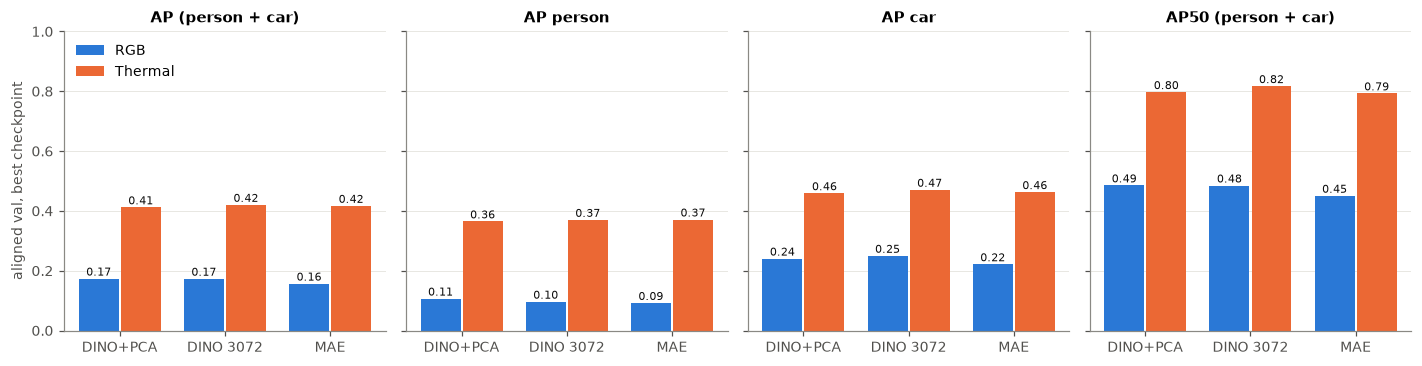

In [6]:
METRICS = [("AP", "AP (person + car)"), ("AP_person", "AP person"), ("AP_car", "AP car"), ("AP50", "AP50 (person + car)")]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
w = 0.38
for ax, (k, title) in zip(axes, METRICS):
    for j, m in enumerate(MODS):
        vals = [B[f"aligned_{b}_{m}"][k] for b in BACKBONES]
        xs = np.arange(3) + (j - 0.5) * (w + 0.02)
        ax.bar(xs, vals, w, color=MOD_COLOR[m], label=MOD_LABEL[m])
        for xi, v in zip(xs, vals):
            ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=7.5, color=INK)
    ax.set_xticks(range(3), ["DINO+PCA", "DINO 3072", "MAE"])
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("aligned val, best checkpoint")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

## 4. The three questions

In [7]:
# (i) paired H1: thermal vs RGB on the same frames and boxes, per backbone
rows = []
for b in BACKBONES:
    r, t = B[f"aligned_{b}_rgb"], B[f"aligned_{b}_ir"]
    rows.append([BB_LABEL[b]] + [f"{t[k]:.3f} / {r[k]:.3f} = **{t[k] / r[k]:.2f}×**" for k in ("AP", "AP_person", "AP_car")])
display(Markdown("**(i) Thermal / RGB** (same 413 val frames, same boxes)"))
table(["backbone", "AP", "AP person", "AP car"], rows)

# (ii) fixed Cityscapes PCA vs learned Linear(3072 -> 1152), same frozen DINOv2 and head
rows = []
for m in MODS:
    p, l = B[f"aligned_dinopca_{m}"], B[f"aligned_dino3072_{m}"]
    rows.append([MOD_LABEL[m]] + [f"{l[k]:.3f} − {p[k]:.3f} = **{l[k] - p[k]:+.3f}**" for k in ("AP", "AP_person", "AP_car")])
display(Markdown("**(ii) Learned projection − PCA** (DINOv2 3072 → Linear minus DINOv2 + PCA)"))
table(["modality", "AP", "AP person", "AP car"], rows)

# (iii) MAE (fine-tuned ViTDet) vs the best frozen DINOv2 variant
rows = []
for m in MODS:
    a = B[f"aligned_mae_{m}"]
    best_dino = max(("dinopca", "dino3072"), key=lambda b: B[f"aligned_{b}_{m}"]["AP"])
    d = B[f"aligned_{best_dino}_{m}"]
    rows.append([MOD_LABEL[m], BB_LABEL[best_dino]] + [f"{a[k]:.3f} − {d[k]:.3f} = **{a[k] - d[k]:+.3f}**" for k in ("AP", "AP_person", "AP_car")])
display(Markdown("**(iii) MAE − best DINOv2 head**"))
table(["modality", "best DINOv2", "AP", "AP person", "AP car"], rows)

**(i) Thermal / RGB** (same 413 val frames, same boxes)

| backbone | AP | AP person | AP car |
|---|---|---|---|
| DINOv2 + PCA | 0.412 / 0.174 = **2.37×** | 0.365 / 0.107 = **3.41×** | 0.459 / 0.241 = **1.91×** |
| DINOv2 3072 → Linear | 0.420 / 0.173 = **2.43×** | 0.370 / 0.096 = **3.84×** | 0.471 / 0.250 = **1.88×** |
| MAE ViT-B (fine-tuned) | 0.417 / 0.157 = **2.66×** | 0.371 / 0.092 = **4.02×** | 0.463 / 0.222 = **2.09×** |

**(ii) Learned projection − PCA** (DINOv2 3072 → Linear minus DINOv2 + PCA)

| modality | AP | AP person | AP car |
|---|---|---|---|
| RGB | 0.173 − 0.174 = **-0.001** | 0.096 − 0.107 = **-0.010** | 0.250 − 0.241 = **+0.009** |
| Thermal | 0.420 − 0.412 = **+0.008** | 0.370 − 0.365 = **+0.005** | 0.471 − 0.459 = **+0.011** |

**(iii) MAE − best DINOv2 head**

| modality | best DINOv2 | AP | AP person | AP car |
|---|---|---|---|---|
| RGB | DINOv2 + PCA | 0.157 − 0.174 = **-0.017** | 0.092 − 0.107 = **-0.015** | 0.222 − 0.241 = **-0.019** |
| Thermal | DINOv2 3072 → Linear | 0.417 − 0.420 = **-0.003** | 0.371 − 0.370 = **+0.001** | 0.463 − 0.471 = **-0.008** |

**(i) Paired H1: thermal ≫ RGB, for every backbone.** Thermal gives 2.4–2.7× the RGB AP on the same frames and boxes,
with the largest ratio for **person (3.4–4.0×)**. The ranking agrees with H1 and with F8 on FLIR v2, but the size is
far larger than F8's (v2: thermal 0.330 vs RGB 0.302 AP, 1.09×). §6 shows that much of this gap comes from how the
aligned dataset was built rather than from the sensors, so **it must not be quoted as a sensor effect yet**.

**(ii) PCA costs almost nothing.** The learned projection beats the fixed Cityscapes PCA by +0.008 AP on thermal and
ties on RGB (−0.001), well inside the noise of a 413-frame val set. So the PCA features the world model reads
keep essentially all the detection power of the full 3072-d DINOv2 features *at this head capacity*, on both
modalities (R7 not triggered). On thermal, note that the PCA was fitted on Cityscapes RGB, and it still costs < 0.01.

**(iii) MAE does not beat DINOv2.** Fine-tuned MAE ViT-B ties the best DINOv2 head on thermal (−0.003) and is
slightly behind on RGB (−0.017), even though it trains 107 M parameters end to end against DINOv2's 23 M head and
uses a higher input resolution (512×640 vs 448×560). This compares two recipes, not just two pretrainings (R13).

## 5. Per class and per object size

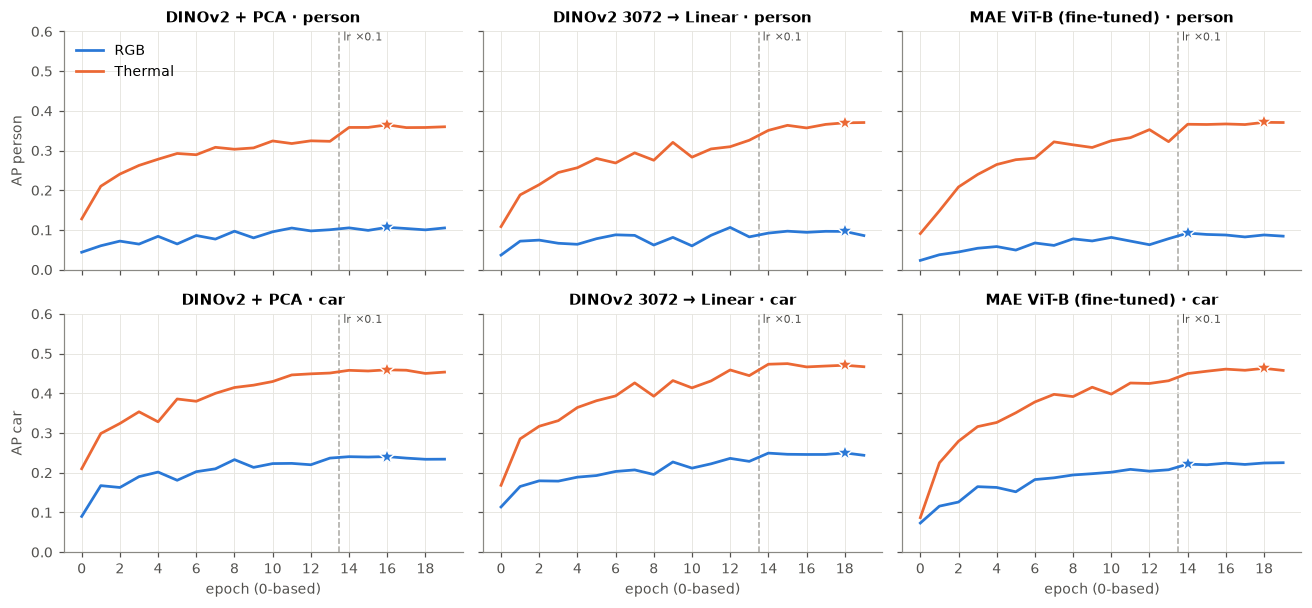

In [8]:
x = np.arange(EPOCHS)
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharex=True, sharey=True)
for col, b in enumerate(BACKBONES):
    for row, (k, name) in enumerate([("AP_person", "person"), ("AP_car", "car")]):
        ax = axes[row, col]
        for m in MODS:
            h = f"aligned_{b}_{m}"
            ax.plot(x, VAL[h][k], color=MOD_COLOR[m], lw=1.8, label=MOD_LABEL[m])
            ax.plot(BEST[h], VAL[h][k][BEST[h]], marker="*", ms=11, color=MOD_COLOR[m], mec="white", mew=1, zorder=5)
        mark_lr_drop(ax)
        ax.set_title(f"{BB_LABEL[b]} · {name}")
    axes[1, col].set_xlabel("epoch (0-based)")
for row, name in enumerate(["AP person", "AP car"]):
    axes[row, 0].set_ylabel(name)
axes[0, 0].set_ylim(0, 0.6)
axes[0, 0].legend(loc="upper left")
for ax in axes[1]:
    ax.set_xticks(range(0, EPOCHS, 2))
fig.tight_layout()
plt.show()

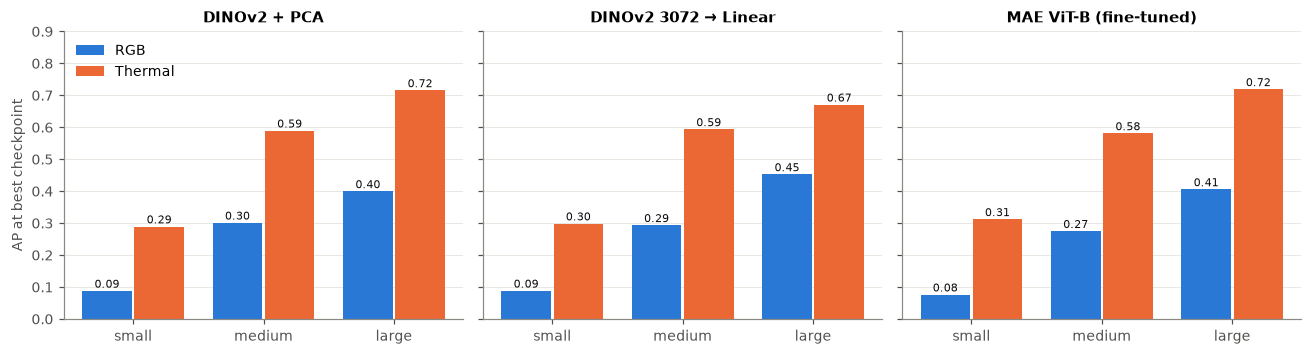

In [9]:
SIZES = [("APs", "small"), ("APm", "medium"), ("APl", "large")]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=True)
w = 0.38
for ax, b in zip(axes, BACKBONES):
    for j, m in enumerate(MODS):
        vals = [B[f"aligned_{b}_{m}"][k] for k, _ in SIZES]
        xs = np.arange(3) + (j - 0.5) * (w + 0.02)
        ax.bar(xs, vals, w, color=MOD_COLOR[m], label=MOD_LABEL[m])
        for xi, v in zip(xs, vals):
            ax.text(xi, v + 0.01, f"{v:.2f}", ha="center", fontsize=7.5, color=INK)
    ax.set_xticks(range(3), [s for _, s in SIZES])
    ax.set_title(BB_LABEL[b])
    ax.grid(axis="x", visible=False)
axes[0].set_ylim(0, 0.9)
axes[0].set_ylabel("AP at best checkpoint")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

- **Car is easier than person in every head.** In RGB, person is the weak point (AP 0.09–0.11, AP50 0.33–0.35);
  in thermal person reaches 0.37, close to car (0.46–0.47). Warm bodies stand out in thermal, which fits H1.
- **Thermal wins in every size bucket**, by 3.3–4.1× on small objects (APs 0.29–0.31 vs 0.08–0.09).
  MAE has the best small-object AP in thermal (0.312), plausibly from its finer 512×640 input.
- Backbone differences per class and size stay within ≈ 0.01–0.05, with no consistent winner, except that MAE is
  last on RGB in AP, AP50, person, car, APs and APm.

## 6. Why is RGB so low? Box fit, not detection alone

RGB here (0.17 AP) is far below the F8 RGB head on FLIR v2 (0.30 AP) while thermal is *higher* (0.41 vs 0.33).
If RGB were simply a weaker sensor, its AP50 and its strict-IoU AP would fall together. Below: how much of the AP50
survives at stricter IoU, with the F8 FLIR v2 heads as a reference for the ratio only (R12: no cross-dataset AP comparison).

In [10]:
# Localisation quality: how much AP survives from the loose IoU 0.5 to the strict IoU 0.75 / 0.5:0.95 criteria.
# Reference rows: the F8 FLIR v2 heads (det_rgb / det_ir). Different dataset (R12), so their AP is NOT compared;
# only the *ratio*, which says whether RGB boxes are inherently harder to localise than thermal ones.
# F8 val metrics of the best epoch, from the two F8 run dirs (identified by the SLURM job in their best_ckpt).
F8_JOBS = {"slurm-5526115": "det_rgb", "slurm-5526116": "det_ir"}  # F8 full runs, git b81ef6c
F8 = {}
for p in sorted((OUT / "detection/2026-10-27").glob("*/train_summary.json")):
    s = read_json(p)
    (k,) = [n for j, n in F8_JOBS.items() if f"/{j}/" in s["best_ckpt"]] or [None]
    if k is None:
        continue
    v = read_json(p.parent / "val_metrics" / f"epoch_{s['best_epoch']:03d}.json")["metrics"]
    assert np.isclose(v["AP"], s["best_val_AP"]), p
    F8[k] = v
assert sorted(F8) == ["det_ir", "det_rgb"], sorted(F8)


def loc_row(name, ds, v):
    return [name, ds, v["AP50"], v["AP75"], v["AP75"] / v["AP50"], v["AP_car"] / v["AP50_car"],
            v["AP_person"] / v["AP50_person"]]


rows = [loc_row(f"{BB_LABEL[bb(h)]} · {MOD_LABEL[mod(h)]}", "aligned v1", B[h]) for h in HEADS]
rows += [loc_row(f"F8 {k} (DINOv2 + PCA)", "FLIR v2 (ref.)", v) for k, v in F8.items()]
table(["head", "dataset", "AP50", "AP75", "AP75 / AP50", "AP / AP50 car", "AP / AP50 person"], rows)

| head | dataset | AP50 | AP75 | AP75 / AP50 | AP / AP50 car | AP / AP50 person |
|---|---|---|---|---|---|---|
| DINOv2 + PCA · RGB | aligned v1 | 0.485 | 0.085 | 0.176 | 0.389 | 0.303 |
| DINOv2 + PCA · Thermal | aligned v1 | 0.797 | 0.363 | 0.455 | 0.555 | 0.476 |
| DINOv2 3072 → Linear · RGB | aligned v1 | 0.485 | 0.087 | 0.178 | 0.402 | 0.277 |
| DINOv2 3072 → Linear · Thermal | aligned v1 | 0.817 | 0.375 | 0.459 | 0.556 | 0.469 |
| MAE ViT-B (fine-tuned) · RGB | aligned v1 | 0.451 | 0.077 | 0.172 | 0.387 | 0.281 |
| MAE ViT-B (fine-tuned) · Thermal | aligned v1 | 0.793 | 0.380 | 0.479 | 0.558 | 0.491 |
| F8 det_rgb (DINOv2 + PCA) | FLIR v2 (ref.) | 0.573 | 0.279 | 0.487 | 0.649 | 0.497 |
| F8 det_ir (DINOv2 + PCA) | FLIR v2 (ref.) | 0.626 | 0.312 | 0.498 | 0.648 | 0.515 |

- **RGB loses most of its AP between IoU 0.5 and 0.75**: AP75/AP50 is 0.17–0.18 for every RGB head vs 0.46–0.48 for
  thermal. On FLIR v2 the two modalities localise *equally* well (0.49 vs 0.50). The RGB heads find the objects
  (AP50 car ≈ 0.62) but their boxes do not match the GT tightly.
- That points to the **annotation geometry**: aligned FLIR v1 has one annotation per pair, and the RGB frame is warped
  into the thermal frame. If the boxes were drawn on thermal (R12's open question), any registration error, parallax
  (the cameras sit apart, so near objects shift more) or timing offset moves the true RGB object off its box.
  The figure below shows the geometry.

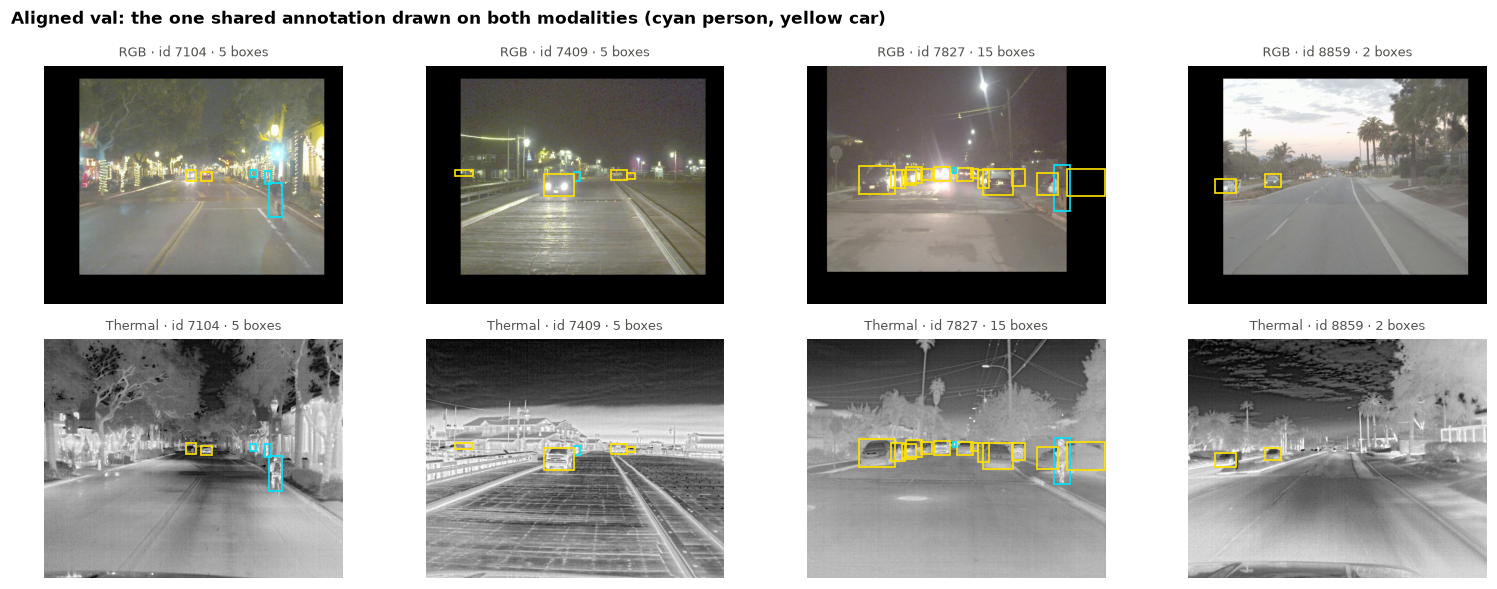

In [11]:
from PIL import Image

from irwm.data.aligned import AlignedSplit
from irwm.utils.paths import load_env

load_env()  # IRWM_DATA_ROOT from <repo>/.env

ALN = {m: AlignedSplit.load(m, "val") for m in ("rgb", "thermal")}
ids = ALN["rgb"].image_ids()
pick = [int(ids[i]) for i in np.linspace(0, len(ids) - 1, 4).astype(int)]
CLS_EDGE = {0: "#00e5ff", 1: "#ffe100"}  # person cyan, car yellow: high contrast on both RGB and grey thermal
fig, axes = plt.subplots(2, len(pick), figsize=(14, 5.4))
for row, iid in enumerate(pick):
    for col, m in enumerate(("rgb", "thermal")):
        r = ALN[m].by_image_id(iid)
        ax = axes[col, row]
        ax.imshow(Image.open(r.path).convert("RGB"))
        for (x0, y0, bw, bh), lab in zip(r.boxes, r.labels):
            ax.add_patch(plt.Rectangle((x0, y0), bw, bh, fill=False, lw=1.1, ec=CLS_EDGE[int(lab)]))
        ax.set_axis_off()
        ax.set_title(f"{'RGB' if m == 'rgb' else 'Thermal'} · id {iid} · {len(r.boxes)} boxes", fontsize=8.5,
                     fontweight="normal", color=MUTED)
fig.suptitle("Aligned val: the one shared annotation drawn on both modalities (cyan person, yellow car)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

In [12]:
# How much of each RGB frame is real image, and how many of the shared boxes fall on its black border?
# Content mask: pixels with max channel > 10 (the border is pure black; JPEG noise stays below that).
def rgb_stats(r):
    img = np.asarray(Image.open(r.path).convert("RGB"))
    content = img.max(axis=2) > 10
    out = []
    for x0, y0, bw, bh in r.boxes.astype(int):
        patch = content[y0:y0 + max(bh, 1), x0:x0 + max(bw, 1)]
        out.append(patch.mean() if patch.size else 0.0)
    return content.mean(), np.array(out), r.labels


COV = [rgb_stats(r) for r in ALN["rgb"]]
area = np.array([c[0] for c in COV])
inside = np.concatenate([c[1] for c in COV])
labs = np.concatenate([c[2] for c in COV])

rows = [["RGB frame area that is image (median, p10–p90)",
         f"{np.median(area):.2f} ({np.percentile(area, 10):.2f}–{np.percentile(area, 90):.2f})"]]
for lab, name in ((0, "person"), (1, "car")):
    sel = labs == lab
    rows.append([f"{name} boxes, share lying ≥ 50 % on the RGB black border",
                 f"{(inside[sel] < 0.5).mean():.1%} of {sel.sum():,}"])
    rows.append([f"{name} boxes, share lying entirely on the black border", f"{(inside[sel] == 0).mean():.1%}"])
table(["aligned val (413 frames)", "value"], rows)

| aligned val (413 frames) | value |
|---|---|
| RGB frame area that is image (median, p10–p90) | 0.69 (0.67–0.69) |
| person boxes, share lying ≥ 50 % on the RGB black border | 1.1% of 1,060 |
| person boxes, share lying entirely on the black border | 0.8% |
| car boxes, share lying ≥ 50 % on the RGB black border | 4.2% of 2,325 |
| car boxes, share lying entirely on the black border | 0.4% |

- Every RGB frame is the RGB image **resampled into the thermal geometry**: only ≈ 69 % of the 640×512 frame is image,
  the rest is black border. The RGB scene is therefore shown ≈ 17 % smaller (linear) than in the native FLIR v2
  frames, which alone makes small objects harder.
- Boxes on the black border are rare (≤ 4 % of car boxes lie mostly on it), so the border is **not** the main
  cause; the low AP75/AP50 ratio is. Many frames are at night (e.g. ids 7104, 7409, 7827), where thermal has a
  natural advantage; a mean-luminance proxy could not separate night from day (auto-gain keeps night frames bright),
  so the day/night share is not quantified here.

**Consequence for H1.** The aligned dataset removes the annotation *count* asymmetry of FLIR v2 (R10), but it
replaces it with a **geometry asymmetry in favour of thermal**. The paired comparison is only fair at a loose IoU:
at AP50, thermal still wins (0.79–0.82 vs 0.45–0.49, 1.6–1.8×), and at AP50 person 0.76–0.79 vs 0.33–0.35.

## 7. TIDE error analysis

[TIDE](https://arxiv.org/abs/2008.08115) (Bolya et al., ECCV 2020) splits the AP50 a detector loses into error types.
Every false positive at IoU 0.5 gets one type: **Loc** (right class, IoU with its GT in [0.1, 0.5)), **Cls** (IoU
≥ 0.5 with a GT of the other class), **Cls+Loc** (both wrong), **Dupe** (its GT was already taken by a
higher-scoring box), **Bkg** (IoU < 0.1 with every GT). Unmatched GT boxes that no Cls/Loc error points at are
**Miss**. Each type's weight is **ΔAP50**: the AP50 gained when an oracle fixes *only* that type (Loc: snap the
box to its GT; Cls: relabel; others: suppress; Miss: drop those GT boxes) and the evaluation is re-run.
"all FP" and "all FN" are the two summary oracles. The Δs overlap, so they do not add up to 100 − AP50.

Computed with `irwm.eval.tide` (numpy, no new dependency; `tests/test_tide.py` checks one case per type and that
its base AP50 equals pycocotools' to 1e-12). Detections are F19's saved files, for **both splits** and all
**12 train → test cells** (in-domain and cross-modal), produced on the cluster by

```bash
bash slurm/eval_aligned.sh ctcomp3              # test (align_validation, 1,013 pairs): the F19 Table B run
bash slurm/eval_aligned.sh ctcomp3 split=val    # val (413 pairs): same split as §2–§6
```

(SLURM 5532481 / 5532482, git `11ccb4d`, L4), copied into `outputs/`. The detection files are opened from the paths
each run's `eval_aligned.json` lists, and checked against its SHA-256. Every cell's TIDE AP50 must equal the AP50
that F19 recorded for it (same COCO matching). The val cells re-score the exported checkpoints, so their in-domain
AP50 is also checked against the training-time val AP50 (§3). The test numbers come from a split nothing was
selected on.

**What §6 predicts.** If the shared boxes fit the thermal objects and not the RGB ones, **Loc should be the
largest RGB error, far larger than thermal's Loc**, while Miss and Bkg (whether the object is seen at all) should
be much closer between the modalities. If RGB instead had mostly Miss/Bkg errors, the gap would be about
detection itself, not box geometry.

In [13]:
import gzip

from irwm.data.aligned import AlignedSplit
from irwm.eval.tide import ERROR_TYPES, SPECIAL_TYPES, tide

TEST_MODS = {"rgb": "rgb", "ir": "thermal"}  # head suffix -> AlignedSplit modality
SPLITS = ["val", "test"]
CELLS = [(h, t) for h in HEADS for t in ("rgb", "ir")]  # (head, test modality); in-domain iff mod(h) == t


def load_detections(split, head, test_mod):
    """F19's detection file for one cell, from the path and SHA-256 its eval_aligned.json records."""
    run = F19[split][1]
    entry = run["detections"][head][TEST_MODS[test_mod]]  # path relative to the output root
    raw = (OUT / entry["path"]).read_bytes()
    assert hashlib.sha256(raw).hexdigest() == entry["sha256"], f"{entry['path']} differs from the run's SHA-256"
    obj = json.loads(gzip.decompress(raw))
    assert (obj["head"], obj["modality"], obj["split"], obj["dataset"]) == \
        (head, TEST_MODS[test_mod], split, "aligned_v1"), entry["path"]
    assert obj["n_images"] == entry["n_images"] and len(obj["detections"]) == entry["n_detections"], entry["path"]
    return obj


TIDE, GT = {}, {}
for split in SPLITS:
    for h, t in CELLS:
        obj = load_detections(split, h, t)
        key = (TEST_MODS[t], split)
        if key not in GT:
            GT[key] = AlignedSplit.load(TEST_MODS[t], split).to_coco_gt()
        assert obj["n_images"] == len(GT[key]["images"]), (split, h, t)
        r = TIDE[(split, h, t)] = tide(GT[key], obj["detections"])
        ap50_run = F19[split][1]["cells"][h][TEST_MODS[t]]["AP50_person_car"]
        assert abs(r.ap50 - ap50_run) < 1e-9, (split, h, t, r.ap50, ap50_run)  # same matching as coco_map
print({s: f"{sum(k[0] == s for k in TIDE)}/{len(CELLS)} cells, AP50 = F19 run, sha256 ok" for s in SPLITS})

# The val in-domain cells re-score the exported (best) checkpoints: their AP50 must match the training-time val AP50.
for h in HEADS:
    r = TIDE[("val", h, mod(h))]
    assert abs(r.ap50 - B[h]["AP50"]) < 0.01, (h, r.ap50, B[h]["AP50"])
    print(f"{h:22s} val AP50: TIDE {r.ap50:.4f} vs training-time {B[h]['AP50']:.4f}")

{'val': '12/12 cells, AP50 = F19 run, sha256 ok', 'test': '12/12 cells, AP50 = F19 run, sha256 ok'}
aligned_dinopca_rgb    val AP50: TIDE 0.4863 vs training-time 0.4854
aligned_dinopca_ir     val AP50: TIDE 0.7979 vs training-time 0.7973
aligned_dino3072_rgb   val AP50: TIDE 0.4853 vs training-time 0.4850
aligned_dino3072_ir    val AP50: TIDE 0.8176 vs training-time 0.8173
aligned_mae_rgb        val AP50: TIDE 0.4510 vs training-time 0.4507
aligned_mae_ir         val AP50: TIDE 0.7932 vs training-time 0.7931


### 7.1 In-domain cells

Each head on its own modality. Colour = modality as everywhere; one panel per error type, all on the same scale.

**In-domain TIDE, aligned val** (ΔAP50 in points: AP50 gained by fixing only that type)

| head | test | AP50 | Δ Cls | Δ Loc | Δ Cls+Loc | Δ Dupe | Δ Bkg | Δ Miss | Δ all FP | Δ all FN | # Loc | # Miss |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| DINOv2 + PCA · RGB | RGB | 48.627 | 0.143 | 16.348 | 0.357 | 0.839 | 3.663 | 1.406 | 30.086 | 12.016 | 17934 | 89 |
| DINOv2 + PCA · Thermal | Thermal | 79.792 | 0.077 | 4.929 | 0.335 | 1.327 | 3.562 | 0.315 | 15.753 | 3.571 | 16724 | 15 |
| DINOv2 3072 → Linear · RGB | RGB | 48.532 | 0.148 | 15.818 | 0.413 | 0.818 | 4.173 | 0.923 | 33.646 | 9.801 | 17449 | 63 |
| DINOv2 3072 → Linear · Thermal | Thermal | 81.761 | 0.043 | 4.438 | 0.311 | 1.374 | 4.034 | 0.161 | 14.774 | 2.636 | 16627 | 8 |
| MAE ViT-B (fine-tuned) · RGB | RGB | 45.098 | 0.213 | 15.982 | 0.734 | 1.247 | 3.897 | 1.125 | 33.120 | 11.631 | 16643 | 77 |
| MAE ViT-B (fine-tuned) · Thermal | Thermal | 79.320 | 0.038 | 3.571 | 0.343 | 1.873 | 3.429 | 1.257 | 14.740 | 4.766 | 15489 | 45 |

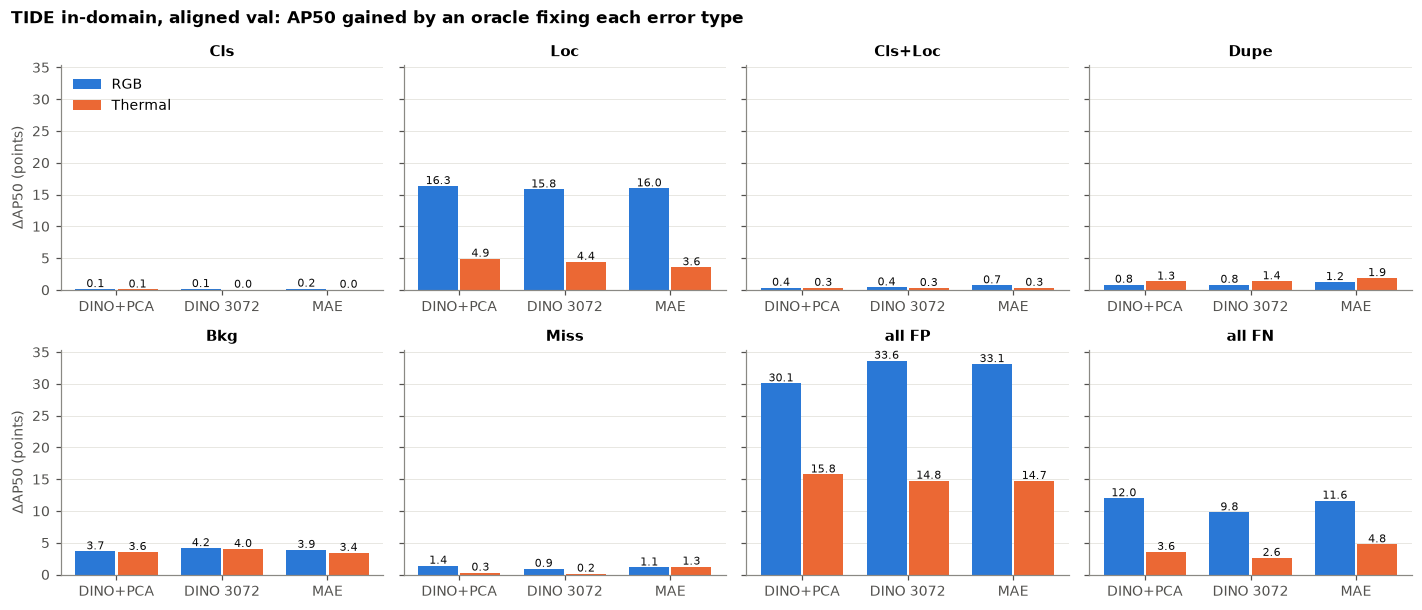

**In-domain TIDE, aligned test** (ΔAP50 in points: AP50 gained by fixing only that type)

| head | test | AP50 | Δ Cls | Δ Loc | Δ Cls+Loc | Δ Dupe | Δ Bkg | Δ Miss | Δ all FP | Δ all FN | # Loc | # Miss |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| DINOv2 + PCA · RGB | RGB | 70.252 | 0.047 | 8.576 | 0.250 | 0.970 | 5.226 | 0.704 | 21.332 | 6.205 | 49562 | 88 |
| DINOv2 + PCA · Thermal | Thermal | 80.173 | 0.078 | 5.034 | 0.148 | 0.946 | 4.671 | 0.425 | 15.371 | 3.082 | 53549 | 46 |
| DINOv2 3072 → Linear · RGB | RGB | 71.448 | 0.065 | 8.177 | 0.204 | 0.996 | 5.056 | 0.524 | 20.136 | 5.861 | 46177 | 60 |
| DINOv2 3072 → Linear · Thermal | Thermal | 81.053 | 0.052 | 4.981 | 0.126 | 0.866 | 4.749 | 0.345 | 14.492 | 3.170 | 52656 | 31 |
| MAE ViT-B (fine-tuned) · RGB | RGB | 67.453 | 0.092 | 7.679 | 0.223 | 1.377 | 6.147 | 0.831 | 23.636 | 6.077 | 45888 | 103 |
| MAE ViT-B (fine-tuned) · Thermal | Thermal | 78.259 | 0.040 | 5.063 | 0.153 | 1.199 | 5.734 | 0.440 | 17.780 | 2.992 | 47267 | 47 |

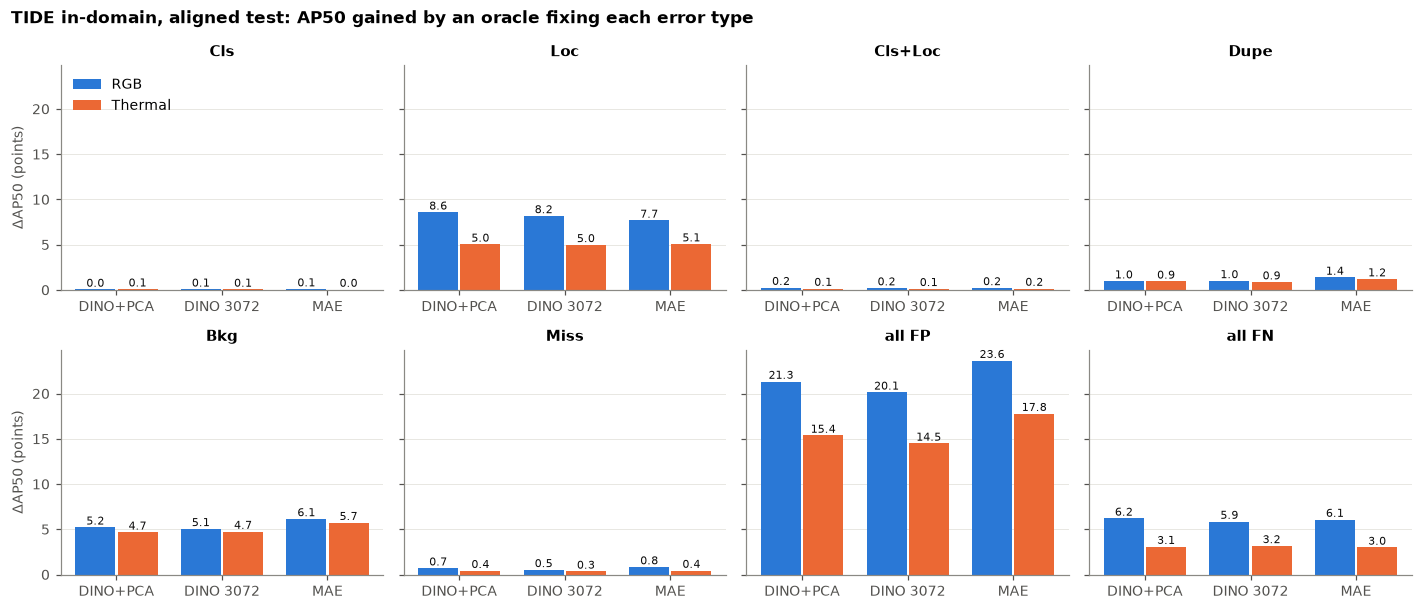

In [14]:
TYPE_LABEL = {"Cls": "Cls", "Loc": "Loc", "Both": "Cls+Loc", "Dupe": "Dupe", "Bkg": "Bkg", "Miss": "Miss",
              "FP": "all FP", "FN": "all FN"}


def tide_rows(split, cells):
    rows = []
    for h, t in cells:
        r = TIDE.get((split, h, t))
        if r is None:
            continue
        rows.append([f"{BB_LABEL[bb(h)]} · {MOD_LABEL[mod(h)]}", MOD_LABEL[t], 100 * r.ap50]
                    + [100 * r.delta[k] for k in ERROR_TYPES + SPECIAL_TYPES]
                    + [r.counts["Loc"], r.counts["Miss"]])
    return rows


def tide_bars(split, title):
    if not any((split, h, mod(h)) in TIDE for h in HEADS):
        print(f"{split}: no in-domain detections yet")
        return
    types = list(ERROR_TYPES) + list(SPECIAL_TYPES)
    fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), sharey=True)  # one scale: types compare directly
    w = 0.38
    for ax, k in zip(axes.flat, types):
        for j, m in enumerate(MODS):
            vals = [100 * TIDE[(split, f"aligned_{b}_{m}", m)].delta[k] if (split, f"aligned_{b}_{m}", m) in TIDE
                    else np.nan for b in BACKBONES]
            xs = np.arange(3) + (j - 0.5) * (w + 0.02)
            ax.bar(xs, vals, w, color=MOD_COLOR[m], label=MOD_LABEL[m])
            for xi, v in zip(xs, vals):
                if np.isfinite(v):
                    ax.text(xi, v + 0.3, f"{v:.1f}", ha="center", fontsize=7.5, color=INK)
        ax.set_xticks(range(3), ["DINO+PCA", "DINO 3072", "MAE"])
        ax.set_title(TYPE_LABEL[k])
        ax.grid(axis="x", visible=False)
    axes[0, 0].set_ylabel("ΔAP50 (points)")
    axes[1, 0].set_ylabel("ΔAP50 (points)")
    axes[0, 0].legend(loc="upper left")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


HEADER = ["head", "test", "AP50"] + [f"Δ {TYPE_LABEL[k]}" for k in ERROR_TYPES + SPECIAL_TYPES] + ["# Loc", "# Miss"]
for split in SPLITS:
    rows = tide_rows(split, [(h, mod(h)) for h in HEADS])
    if rows:
        display(Markdown(f"**In-domain TIDE, aligned {split}** (ΔAP50 in points: AP50 gained by fixing only that type)"))
        table(HEADER, rows)
        tide_bars(split, f"TIDE in-domain, aligned {split}: AP50 gained by an oracle fixing each error type")

*Commentary pending: written once the detection files are in.*

### 7.2 Cross-modal cells and what the shift adds

RGB heads on thermal frames and thermal heads on RGB frames (the same frames and boxes, so no label mismatch).
The bars subtract the in-domain head's ΔAP50 from the cross-modal head's, on the **same test frames**: a positive
bar is an error type the modality shift creates. Colour = the training modality of the cross-modal head; shade =
backbone. ΔAP50 is bounded by the AP that is left, so a head with a very low base AP can show *smaller* Δs; read
the counts (# Loc, # Miss) next to the Δs.

**Cross-modal TIDE, aligned val** (RGB heads on thermal, thermal heads on RGB)

| head | test | AP50 | Δ Cls | Δ Loc | Δ Cls+Loc | Δ Dupe | Δ Bkg | Δ Miss | Δ all FP | Δ all FN | # Loc | # Miss |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| DINOv2 + PCA · RGB | Thermal | 60.275 | 0.333 | 9.419 | 0.616 | 1.069 | 3.756 | 1.272 | 24.379 | 10.206 | 16076 | 60 |
| DINOv2 + PCA · Thermal | RGB | 34.729 | 0.123 | 19.682 | 0.573 | 0.652 | 2.136 | 2.060 | 30.618 | 17.106 | 19266 | 183 |
| DINOv2 3072 → Linear · RGB | Thermal | 62.496 | 0.167 | 8.538 | 0.431 | 1.266 | 4.778 | 0.641 | 26.118 | 7.611 | 13711 | 32 |
| DINOv2 3072 → Linear · Thermal | RGB | 37.798 | 0.181 | 18.829 | 0.686 | 0.880 | 2.158 | 2.507 | 30.024 | 16.942 | 18906 | 195 |
| MAE ViT-B (fine-tuned) · RGB | Thermal | 37.770 | 0.205 | 13.743 | 0.666 | 0.957 | 7.374 | 1.649 | 36.488 | 12.938 | 13658 | 148 |
| MAE ViT-B (fine-tuned) · Thermal | RGB | 28.038 | 0.121 | 15.559 | 0.918 | 0.774 | 2.491 | 2.421 | 33.843 | 15.409 | 17764 | 279 |

**Cross-modal TIDE, aligned test** (RGB heads on thermal, thermal heads on RGB)

| head | test | AP50 | Δ Cls | Δ Loc | Δ Cls+Loc | Δ Dupe | Δ Bkg | Δ Miss | Δ all FP | Δ all FN | # Loc | # Miss |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| DINOv2 + PCA · RGB | Thermal | 67.474 | 0.098 | 10.536 | 0.331 | 0.985 | 3.837 | 0.775 | 21.635 | 7.728 | 50145 | 99 |
| DINOv2 + PCA · Thermal | RGB | 56.220 | 0.065 | 15.074 | 0.258 | 0.533 | 5.046 | 1.498 | 24.968 | 11.826 | 53380 | 246 |
| DINOv2 3072 → Linear · RGB | Thermal | 69.846 | 0.069 | 9.700 | 0.303 | 1.110 | 3.927 | 0.588 | 20.748 | 6.865 | 45395 | 71 |
| DINOv2 3072 → Linear · Thermal | RGB | 58.082 | 0.065 | 14.077 | 0.301 | 0.656 | 4.871 | 1.350 | 24.097 | 11.638 | 53770 | 217 |
| MAE ViT-B (fine-tuned) · RGB | Thermal | 48.293 | 0.180 | 12.868 | 0.591 | 1.224 | 5.535 | 1.574 | 32.400 | 11.207 | 41157 | 259 |
| MAE ViT-B (fine-tuned) · Thermal | RGB | 52.526 | 0.058 | 12.918 | 0.320 | 0.698 | 5.581 | 2.032 | 27.177 | 12.220 | 49607 | 347 |

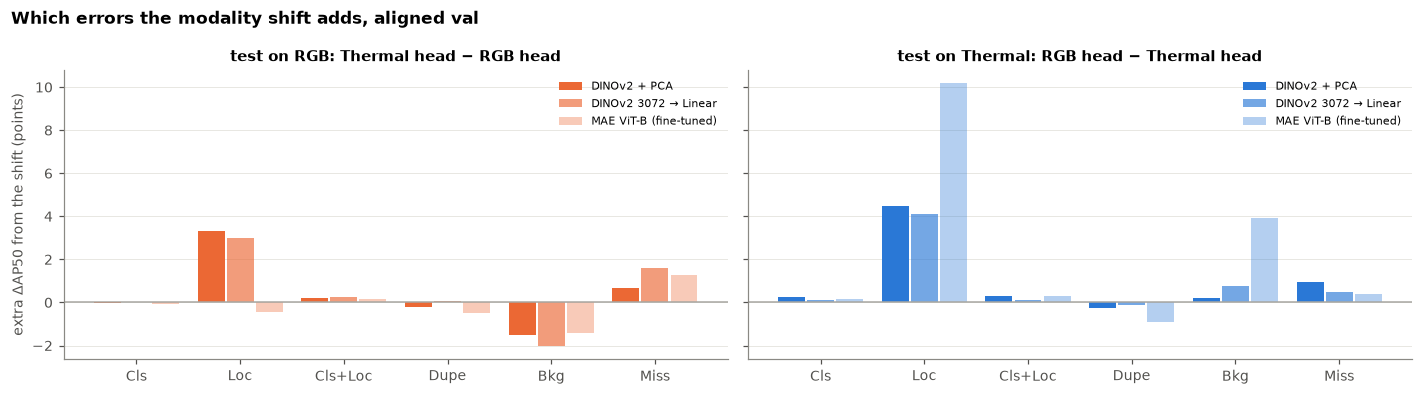

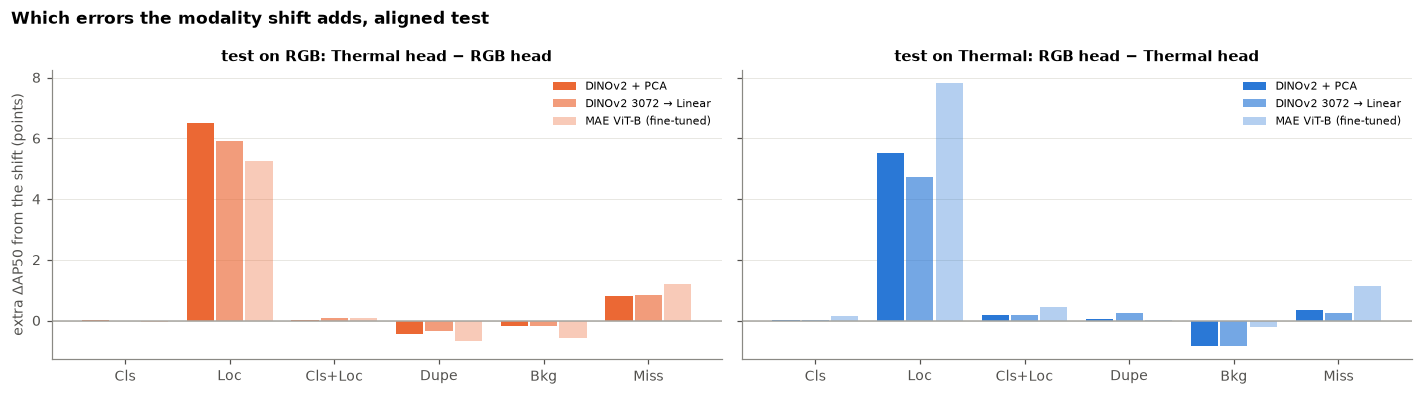

In [15]:
for split in SPLITS:
    rows = tide_rows(split, [(h, t) for h, t in CELLS if t != mod(h)])
    if rows:
        display(Markdown(f"**Cross-modal TIDE, aligned {split}** (RGB heads on thermal, thermal heads on RGB)"))
        table(HEADER, rows)


def shift_bars(split):
    """What the domain shift adds: ΔAP50(cross-modal head) − ΔAP50(in-domain head), on the SAME test frames."""
    if not all((split, h, t) in TIDE for h, t in CELLS):
        print(f"{split}: needs all 12 cells")
        return
    types = list(ERROR_TYPES)
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
    w = 0.26
    for ax, t in zip(axes, MODS):
        src = "ir" if t == "rgb" else "rgb"  # the head trained on the OTHER modality
        for j, b in enumerate(BACKBONES):
            cross, home = TIDE[(split, f"aligned_{b}_{src}", t)], TIDE[(split, f"aligned_{b}_{t}", t)]
            vals = [100 * (cross.delta[k] - home.delta[k]) for k in types]
            xs = np.arange(len(types)) + (j - 1) * (w + 0.02)
            ax.bar(xs, vals, w, color=MOD_COLOR[src], alpha=[1.0, 0.65, 0.35][j], label=BB_LABEL[b])
        ax.axhline(0, color=REF, lw=1)
        ax.set_xticks(range(len(types)), [TYPE_LABEL[k] for k in types])
        ax.set_title(f"test on {MOD_LABEL[t]}: {MOD_LABEL[src]} head − {MOD_LABEL[t]} head")
        ax.grid(axis="x", visible=False)
        ax.legend(loc="best", fontsize=7.5)
    axes[0].set_ylabel("extra ΔAP50 from the shift (points)")
    fig.suptitle(f"Which errors the modality shift adds, aligned {split}", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()


for split in SPLITS:
    shift_bars(split)

*Commentary pending: written once the detection files are in.*

## 8. Training loss

Epoch-mean training loss (full DINO objective incl. auxiliary and denoising terms), log scale; line style = backbone.

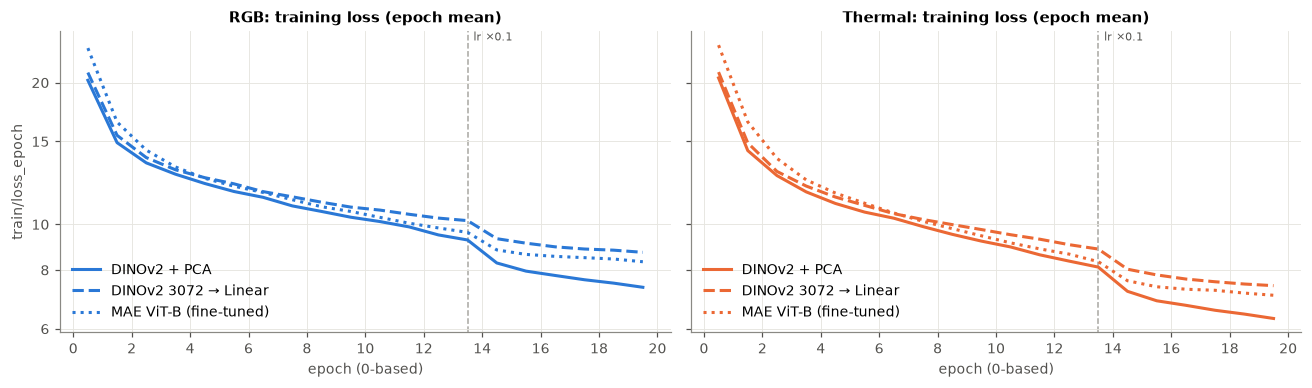

| backbone | modality | loss e0 | loss @best | loss e19 | AP @best | AP e19 | AP e19 − best |
|---|---|---|---|---|---|---|---|
| DINOv2 + PCA | RGB | 20.236 | 7.789 | 7.352 | 0.174 | 0.170 | -0.004 |
| DINOv2 + PCA | Thermal | 20.471 | 6.731 | 6.312 | 0.412 | 0.407 | -0.005 |
| DINOv2 3072 → Linear | RGB | 21.015 | 8.816 | 8.723 | 0.173 | 0.165 | -0.008 |
| DINOv2 3072 → Linear | Thermal | 21.062 | 7.470 | 7.410 | 0.420 | 0.419 | -0.002 |
| MAE ViT-B (fine-tuned) | RGB | 23.686 | 8.826 | 8.330 | 0.157 | 0.155 | -0.002 |
| MAE ViT-B (fine-tuned) | Thermal | 24.030 | 7.146 | 7.071 | 0.417 | 0.414 | -0.003 |

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, m in zip(axes, MODS):
    for b in BACKBONES:
        h = f"aligned_{b}_{m}"
        ax.plot(np.arange(EPOCHS) + 0.5, per_epoch(h, "train/loss_epoch"), color=MOD_COLOR[m], ls=BB_LS[b], lw=2,
                label=BB_LABEL[b])
    mark_lr_drop(ax)
    ax.set_title(f"{MOD_LABEL[m]}: training loss (epoch mean)")
    ax.set_xlabel("epoch (0-based)")
    ax.set_yscale("log")
    ax.set_yticks([6, 8, 10, 15, 20], ["6", "8", "10", "15", "20"])
    ax.minorticks_off()
    ax.set_xticks(range(0, EPOCHS + 1, 2))
    ax.legend()
axes[0].set_ylabel("train/loss_epoch")
fig.tight_layout()
plt.show()

# generalisation gap proxy: loss drop after the best epoch vs AP change after it
rows = []
for h in HEADS:
    loss = per_epoch(h, "train/loss_epoch")
    rows.append([BB_LABEL[bb(h)], MOD_LABEL[mod(h)], loss[0], loss[BEST[h]], loss[-1],
                 VAL[h]["AP"][BEST[h]], VAL[h]["AP"][-1], VAL[h]["AP"][-1] - VAL[h]["AP"][BEST[h]]])
table(["backbone", "modality", "loss e0", "loss @best", "loss e19", "AP @best", "AP e19", "AP e19 − best"], rows)

- Every head's epoch loss falls to 0.29–0.42× of epoch 0 and keeps falling slowly after the best epoch, while val AP
  stays flat: the heads are near convergence on 3.7k frames, not overfitting yet.
- **DINOv2 + PCA reaches the lowest training loss** in both modalities (7.35 / 6.31 at epoch 19 vs 8.72 / 7.41 for the
  learned projection), yet ties it on val AP: the fixed 1152-d PCA features are easier for the head to fit, but
  that does not turn into better detection.
- Thermal loss sits below RGB for every backbone, consistent with the boxes fitting thermal better (§6); loss is
  not comparable across backbones (MAE trains a different detector, ViTDet's DINO head).

## 9. Compute cost

In [17]:
rows = []
for h in HEADS:
    gpu = WB[h]["meta"]["gpu"].replace("NVIDIA ", "").replace("Tesla ", "")
    enc = per_epoch(h, "perf/encode_ms")
    share = per_epoch(h, "perf/encode_share")
    rows.append([h, gpu, f"{np.median(per_epoch(h, 'perf/step_ms')):.0f}", f"{np.median(enc):.0f}",
                 f"{np.median(share):.2f}", f"{np.median(per_epoch(h, 'perf/train_images_per_s')):.1f}",
                 f"{series(h, 'perf/gpu_hours')[1][-1]:.2f}"])
table(["head", "GPU", "step ms", "encode ms", "encode share", "train img/s", "GPU-h"], rows)

| head | GPU | step ms | encode ms | encode share | train img/s | GPU-h |
|---|---|---|---|---|---|---|
| aligned_dinopca_rgb | V100S-PCIE-32GB | 765 | 111 | 0.15 | 19.2 | 1.08 |
| aligned_dinopca_ir | V100S-PCIE-32GB | 762 | 109 | 0.14 | 19.3 | 1.07 |
| aligned_dino3072_rgb | A100-PCIE-40GB | 524 | 45 | 0.09 | 28.1 | 0.74 |
| aligned_dino3072_ir | A100-PCIE-40GB | 527 | 45 | 0.08 | 28.2 | 0.74 |
| aligned_mae_rgb | A100-PCIE-40GB | 880 | 0 | 0.00 | 17.0 | 1.24 |
| aligned_mae_ir | A100-PCIE-40GB | 876 | 0 | 0.00 | 17.2 | 1.23 |

- **dino3072 vs MAE on the same A100**: a MAE step is 1.67× a dino3072 step (877 vs 525 ms), 1.23 vs 0.74 GPU-h for
  20 epochs, for no AP gain. The frozen DINOv2 encoder is 8–9 % of the dino3072 step (45 ms); MAE has no separate
  encode (`encode_ms` = 0, the ViT is trained inside the detector).
- The dinopca heads ran on a V100S (765 ms/step, encoder 15 %), so their cost is **not** comparable with the A100
  runs; the PCA itself adds negligible compute.
- All six fit well inside the L4-sized limits (≤ 1.25 GPU-h each, F18 estimate ≈ 2 L4 GPU-h).

## 10. Takeaways and next steps

**Results (aligned val, preliminary, no CIs):**

| question | answer |
|---|---|
| (i) paired H1 | Thermal > RGB for every backbone: AP 2.4–2.7×, AP50 1.6–1.8×. Inflated by the box geometry (§6). |
| (ii) PCA cost | ≤ 0.01 AP on both modalities; the world model's PCA space keeps the detection power. |
| (iii) DINOv2 vs MAE | Tie on thermal, MAE −0.017 on RGB, at ≈ 1.7× the step cost. |

**Caveats.**
1. §1–§6 are val, not test. F19 has now run on both splits (2026-11-16, git `11ccb4d`); §7 uses its detections,
   but the test Table B (AP, cross-modal 2×2) is not yet discussed here.
2. The RGB/thermal gap is confounded by the shared annotation fitting thermal better (AP75/AP50 0.18 vs 0.47).
   R12's open question ("were the v1 boxes drawn on thermal?") now has strong indirect evidence for *yes*.
3. 413 val frames, one seed, no bootstrap: the backbone differences (≤ 0.02) are within noise.
4. The dinopca run dir was shared; dinopca_ir's numbers come only from its W&B log (verified-equivalent source).
   Its frozen `meta.json` carries the RGB head's val metrics (§1); the weights are correct.

**Suggested next steps.**
- ~~Run F19 on the test set and with `split=val`~~ (done 2026-11-16, §7). Write the §7 commentary, and report the
  H1 comparison at **AP50 alongside AP**, with the AP75/AP50 ratio.
- Check the box geometry directly: overlay GT on RGB for near objects (large boxes) and measure the offset of RGB
  detections to GT (e.g. mean box-centre shift of matched detections); if systematic, the RGB AP is a lower bound.
- ~~Check `frozen/aligned_dinopca_ir/meta.json`~~ (checked in §1): epoch 16 is right, but its `val_metrics` are the RGB
  head's. Re-write them from the W&B log (`4axkuf1b`, epoch 16) on the cluster.